Solve the following differential equations. Plot the functions over the indicated domain.

In [1]:
################################################################################
# IMPORT MODULES
################################################################################
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as intx

(a)
$$
\frac{dy_1}{dx} - y_1 y_2 = 0\\
\frac{dy_2}{dx} - y_1 x - 1 = 0
$$

with boundary conditions

$$ y_1(-2) = 4 $$

$$ y_2(1) = -1 $$

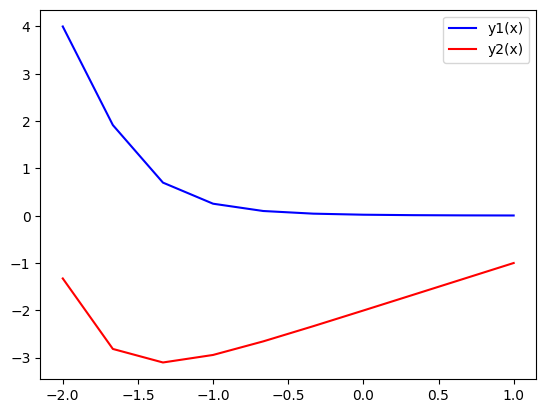

In [2]:
def ode(x,v):
    y1,y2 = v
    dy1 = y1*y2
    dy2 = y1*x+1
    return (dy1,dy2)

def bc(va, vb):
    y1a,y2a = va
    y1b,y2b = vb
    return (y1a-4,y2b+1)

x = np.linspace(-2,1,10)
v0 = np.ones((2,x.size))

res = intx.solve_bvp(ode,bc,x,v0)
y1,y2 = res.sol(x)

plt.plot(x,y1,'b-', label='y1(x)')
plt.plot(x,y2,'r-',label="y2(x)")
plt.legend()
plt.show()

(b)
$$
y'''  - (y'')^2 + 2 y = 0
$$

with boundary conditions

$$
y(0) = -5
$$

$$
y(5) = 1
$$

$$
y'(5) = -2
$$

   Iteration    Max residual  Max BC residual  Total nodes    Nodes added  
       1          2.00e+00       1.32e+00          10             18       
       2          5.85e+01       7.60e-01          28             50       
       3          1.96e+00       5.48e-01          78             131      
       4          9.77e+00       3.95e-01          209            333      
       5          5.61e+03       2.85e-01          542           (853)     
Number of nodes is exceeded after iteration 5. 
Maximum relative residual: 5.61e+03 
Maximum boundary residual: 2.85e-01


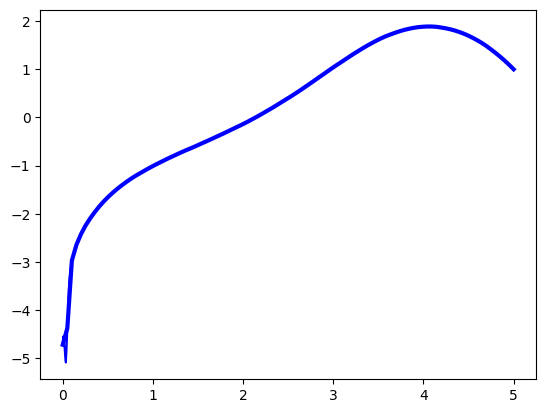

In [5]:
def ode(x,v):
    y,dy,d2y = v
    d3y = (d2y)**2 - 2*y
    return dy,d2y,d3y

def bc(va,vb):
    ya,dya,d2ya = va
    yb,dyb,d2yb = vb
    return ya+5,yb-1,dyb+2

a,b = 0,5
x = np.linspace(a,b,10)
y0 = np.ones((3,x.size))

sol = intx.solve_bvp(ode,bc,x,y0,verbose=2)
x = sol.x
y = sol.y[0]

xd = np.linspace(a,b,100)
yd = sol.sol(xd)[0]

plt.plot(x,y,'b-',ms=10)
plt.plot(xd,yd,'b-',lw=3)
plt.show()